# 01 · EDA Fase 0 - Limpieza y consistencia
**Ticket 1.3** · Bloques: SCB, NEO, EX41, ASEG, TRAC, NHPT

Objetivos (A/C del ticket):
1. Matriz/reporte de completitud por bloque y cohorte.
2. Detección de valores atípicos severos.
3. Validación de consistencia de unidades (pesos y tallas).
4. Lista documentada de anomalías y decisiones de limpieza para el pipeline.

Extras: columnas numéricas guardadas como `object` (nota sobre `_prepare_for_export` en `load_data.py`), cobertura por paciente de cada bloque y tamaño útil para el target de resiliencia (tickets 2.2 / 3.1).

> Datos clínicos confidenciales: este notebook solo exporta **agregados** (conteos y porcentajes). No exportes ni subas filas de pacientes. Los strings sueltos de la sección 3 solo se muestran si `SHOW_EXAMPLES = True` (pueden ser comentarios clínicos).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 160)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM = ROOT / "data" / "interim"
OUT = ROOT / "reports" / "eda_fase_0"
OUT.mkdir(parents=True, exist_ok=True)

EXPECTED = {
    "canguro": 228,
    "tradicional": 213,
    "referencia": 50,
    "referencia_rciu_fenton": 12,
}
MAIN = ["canguro", "tradicional", "referencia"]

# Prefijos verificados con las columnas reales (ASEG incluye 'aseg_' minúscula).
BLOCKS = {
    "SCB": r"^scb",
    "NEO": r"^neo",
    "EX41": r"^ex41",
    "ASEG": r"^aseg",
    "TRAC": r"^trac",
    "NHPT": r"^nhpt",
}
IMAGING_BLOCKS = {"ASEG", "TRAC"}  # bloques de neuroimagen (colas largas esperables)

# True muestra strings sueltos (pueden ser comentarios clínicos): no subas esa salida
SHOW_EXAMPLES = False
MISSING_FLAG = 0.30  # >30% faltante entre pacientes que sí tienen el bloque
LOW_COVERAGE = 90.0  # % de pacientes con datos del bloque por debajo del cual se marca
IQR_K = 3.0  # atípico severo: fuera de [Q1 - 3*IQR, Q3 + 3*IQR]
SENTINELS = [-999, -99, -9, 99, 999, 9999]  # códigos típicos de "sin dato" (SPSS)

ANOM = []  # lista de anomalías / decisiones de limpieza


def add_anom(bloque, columna, tipo, detalle, decision="por definir"):
    ANOM.append(
        {
            "bloque": bloque,
            "columna": columna,
            "tipo": tipo,
            "detalle": detalle,
            "decision_propuesta": decision,
        }
    )

## 1. Carga de cohortes y verificación de tamaños

In [2]:
cohorts = {}
for name, n_exp in EXPECTED.items():
    p = INTERIM / f"{name}.parquet"
    if not p.exists():
        print(f"ERROR  No existe {p} (corre: uv run python -m src.data.load_data)")
        continue
    cohorts[name] = pd.read_parquet(p)
    n = len(cohorts[name])
    ncols = cohorts[name].shape[1]
    estado = "OK" if n == n_exp else "REVISAR"
    print(f"{estado:8s}{name:24s} n={n:4d} (esperado {n_exp}) cols={ncols}")

df = pd.concat(
    [cohorts[c].assign(cohorte=c) for c in MAIN if c in cohorts], ignore_index=True
)
# Strings vacíos cuentan como faltantes
df = df.replace(r"^\s*$", np.nan, regex=True)
print("\nDataset combinado:", df.shape)

OK      canguro                  n= 228 (esperado 228) cols=2267
OK      tradicional              n= 213 (esperado 213) cols=2267
OK      referencia               n=  50 (esperado 50) cols=2268
OK      referencia_rciu_fenton   n=  12 (esperado 12) cols=2268

Dataset combinado: (491, 2269)


## 2. Asignación de columnas a bloques

In [3]:
block_cols = {
    b: [c for c in df.columns if re.search(p, str(c), re.IGNORECASE) and c != "cohorte"]
    for b, p in BLOCKS.items()
}
print(
    pd.Series({b: len(c) for b, c in block_cols.items()}, name="n_columnas").to_frame()
)

      n_columnas
SCB            7
NEO           26
EX41          16
ASEG          98
TRAC         325
NHPT           9


## 3. Tipos de dato: columnas numéricas leídas como `object`
Columnas `object` donde casi todo es numérico y hay strings sueltos. Hay que recastearlas a `float`/`int` en la capa `processed`.

In [4]:
def numeric_disguised(s, min_share=0.9):
    if s.dtype != object and str(s.dtype) not in ("string", "str"):
        return None
    nn = s.dropna()
    if nn.empty:
        return None
    conv = pd.to_numeric(nn, errors="coerce")
    share = conv.notna().mean()
    if share >= min_share:
        bad = nn[conv.isna()].astype(str)
        return share, len(bad), bad.unique()[:5].tolist()
    return None


rows = []
for b, cols in block_cols.items():
    for c in cols:
        r = numeric_disguised(df[c])
        if r:
            share, n_bad, ejemplos = r
            row = {
                "bloque": b,
                "columna": c,
                "pct_numerico": round(100 * share, 1),
                "n_no_numericos": n_bad,
            }
            detalle = f"Numérica como object; {n_bad} valores no numéricos"
            if SHOW_EXAMPLES:
                row["ejemplos"] = ejemplos
                detalle += f" (ej.: {ejemplos})"
            rows.append(row)
            add_anom(
                b,
                c,
                "tipo_object",
                detalle,
                "Recastear a float/int en processed; strings -> NaN o recodificar",
            )
disguised = pd.DataFrame(rows)
print(f"{len(disguised)} columnas numéricas guardadas como object")
disguised

0 columnas numéricas guardadas como object


""


## 4. Cobertura por paciente
Un paciente "tiene" un bloque si tiene **al menos un dato** en él. Distingue el faltante a nivel de paciente (p. ej. sin resonancia) del faltante suelto dentro del bloque.

In [5]:
tiene = {b: df[cols].notna().any(axis=1) for b, cols in block_cols.items() if cols}

rows = []
for b, t in tiene.items():
    agg = t.groupby(df["cohorte"]).agg(["sum", "size"])
    for coh, r in agg.iterrows():
        rows.append(
            {
                "bloque": b,
                "cohorte": coh,
                "n": int(r["size"]),
                "con_datos": int(r["sum"]),
                "pct_con_datos": round(100 * r["sum"] / r["size"], 1),
            }
        )
cobertura = pd.DataFrame(rows)
cobertura.to_csv(OUT / "cobertura_por_bloque.csv", index=False)

for b, sub in cobertura.groupby("bloque"):
    if (sub.pct_con_datos < LOW_COVERAGE).any():
        det = "; ".join(f"{r.cohorte}: {r.con_datos}/{r.n}" for r in sub.itertuples())
        add_anom(
            b,
            "(bloque)",
            "paciente_sin_bloque",
            f"Pacientes con datos -> {det}",
            "Faltante de paciente: no imputar el bloque completo; definir muestra útil",
        )

print("% de pacientes con al menos un dato en el bloque")
cobertura.pivot(index="bloque", columns="cohorte", values="pct_con_datos")

% de pacientes con al menos un dato en el bloque


cohorte,canguro,referencia,tradicional
bloque,,,
ASEG,62.3,74.0,56.3
EX41,100.0,100.0,100.0
NEO,100.0,100.0,100.0
NHPT,100.0,100.0,98.6
SCB,100.0,100.0,100.0
TRAC,60.5,74.0,55.9


## 5. Completitud (valores faltantes)

In [6]:
rows = []
for b, cols in block_cols.items():
    if not cols:
        continue
    for coh, g in df.groupby("cohorte"):
        miss = g[cols].isna().mean()
        rows.append(
            {
                "bloque": b,
                "cohorte": coh,
                "n_cols": len(cols),
                "pct_faltante_medio": round(100 * miss.mean(), 1),
                "n_cols_100%_vacias": int((miss == 1).sum()),
            }
        )
completitud = pd.DataFrame(rows)
completitud.to_csv(OUT / "completitud_resumen.csv", index=False)
completitud

,bloque,cohorte,n_cols,pct_faltante_medio,n_cols_100%_vacias
0,SCB,canguro,7,0.9,0
1,SCB,referencia,7,0.6,0
2,SCB,tradicional,7,0.5,0
3,NEO,canguro,26,14.1,1
4,NEO,referencia,26,34.6,9
5,NEO,tradicional,26,15.2,1
6,EX41,canguro,16,3.0,0
7,EX41,referencia,16,29.9,4
8,EX41,tradicional,16,32.4,4
9,ASEG,canguro,98,38.5,1


In [7]:
def clasificar(total, by_coh, dentro):
    if total == 1:
        return "columna_vacia"
    if by_coh.max() >= 0.9 and by_coh.min() <= 0.3:
        return "faltante_por_cohorte"
    if dentro > MISSING_FLAG:
        return "faltantes_altos"
    return None


DECISION = {
    "columna_vacia": "Excluir (probable encabezado de sección o variable sin datos)",
    "faltante_por_cohorte": "Faltante por diseño probable: no imputar; excluir o usar solo la cohorte que la tiene",
    "faltantes_altos": "Evaluar: excluir de features o imputar (MICE, ticket 3.1)",
}

per_col = []
for b, cols in block_cols.items():
    for c in cols:
        miss = df[c].isna()
        by_coh = miss.groupby(df["cohorte"]).mean()
        dentro = miss[tiene[b]].mean() if tiene[b].any() else np.nan
        tipo = clasificar(miss.mean(), by_coh, dentro)
        row = {
            "bloque": b,
            "columna": c,
            "pct_faltante_total": round(100 * miss.mean(), 1),
            "pct_faltante_con_bloque": round(100 * dentro, 1),
            "patron": tipo,
        }
        for coh, v in by_coh.items():
            row[f"pct_falt_{coh}"] = round(100 * v, 1)
        per_col.append(row)
        if tipo == "faltante_por_cohorte":
            det = ", ".join(f"{k}: {100 * v:.0f}%" for k, v in by_coh.items())
            add_anom(b, c, tipo, f"% faltante por cohorte -> {det}", DECISION[tipo])
        elif tipo:
            det = f"{100 * miss.mean():.1f}% total; {100 * dentro:.1f}% con bloque presente"
            add_anom(b, c, tipo, det, DECISION[tipo])

per_col = pd.DataFrame(per_col)
per_col.to_csv(OUT / "completitud_por_columna.csv", index=False)
print(per_col.groupby(["bloque", "patron"], dropna=False).size().unstack(fill_value=0))

patron  columna_vacia  faltante_por_cohorte  faltantes_altos  NaN
bloque                                                           
ASEG                1                     0                0   97
EX41                0                     5                0   11
NEO                 1                     3                6   16
NHPT                1                     0                3    5
SCB                 0                     0                0    7
TRAC                1                     0                0  324


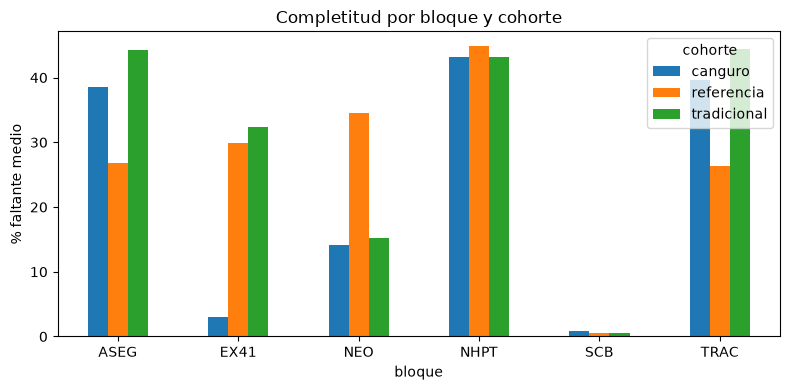

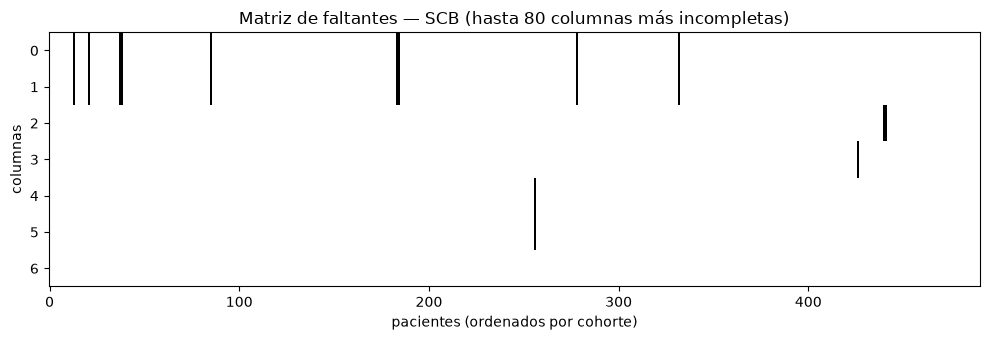

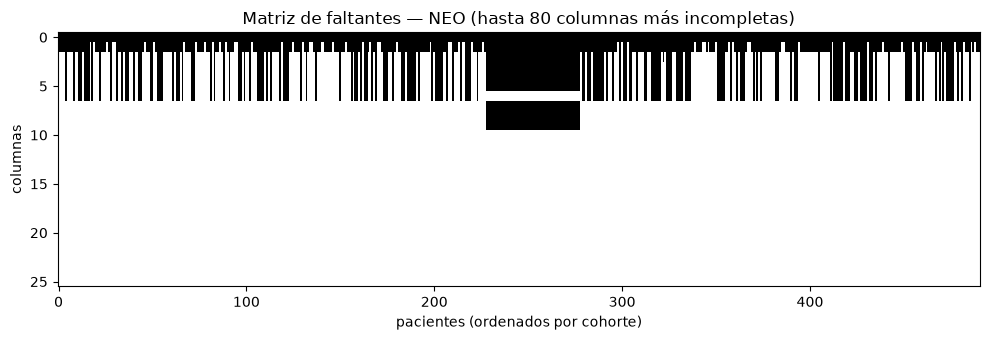

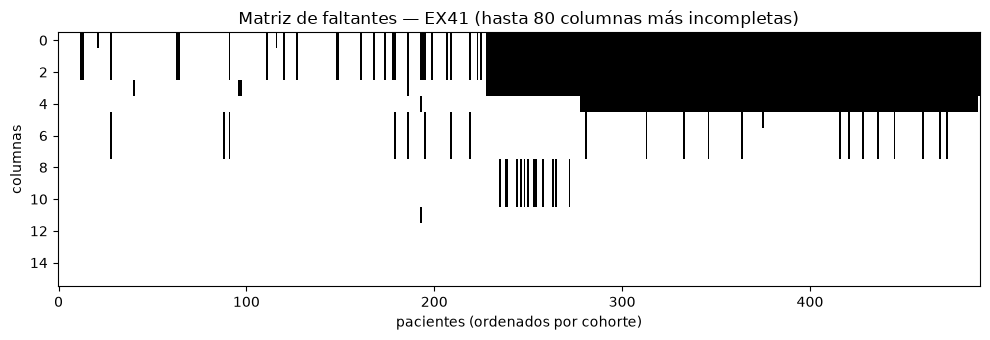

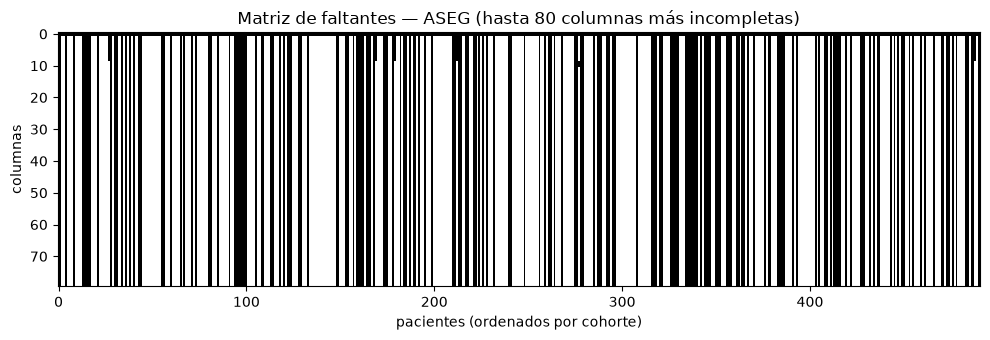

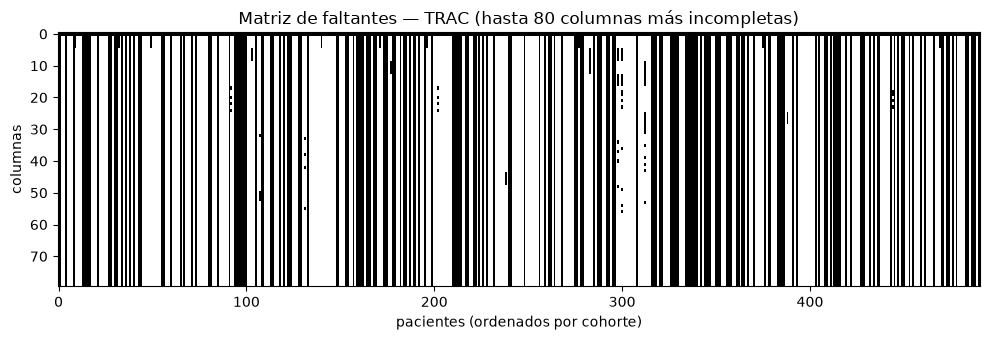

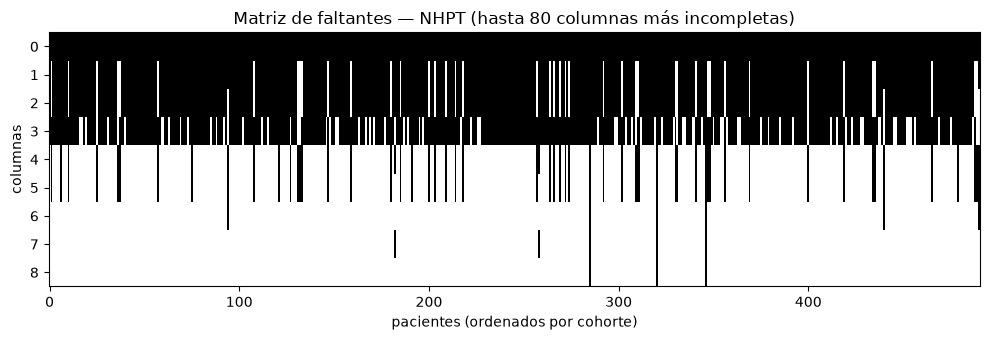

In [8]:
ax = completitud.pivot(
    index="bloque", columns="cohorte", values="pct_faltante_medio"
).plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("% faltante medio")
ax.set_title("Completitud por bloque y cohorte")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "completitud_por_bloque.png", dpi=150)
plt.show()

# Matriz de faltantes por bloque (negro = faltante). Pacientes ordenados por cohorte.
orden = df.sort_values("cohorte", kind="stable")
for b, cols in block_cols.items():
    if not cols:
        continue
    top = df[cols].isna().mean().sort_values(ascending=False).index[:80]
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.imshow(
        orden[top].isna().T.values,
        aspect="auto",
        cmap="gray_r",
        interpolation="nearest",
    )
    ax.set_title(f"Matriz de faltantes — {b} (hasta 80 columnas más incompletas)")
    ax.set_xlabel("pacientes (ordenados por cohorte)")
    ax.set_ylabel("columnas")
    plt.tight_layout()
    plt.savefig(OUT / f"matriz_faltantes_{b}.png", dpi=120)
    plt.show()

## 6. Valores atípicos severos
Regla: fuera de `[Q1 − 3·IQR, Q3 + 3·IQR]` (todas las cohortes juntas; columnas con ≥10 valores distintos). En neuroimagen (ASEG/TRAC) se resume por bloque: las colas largas son esperables y no implican error.

In [9]:
rows = []
for b, cols in block_cols.items():
    for c in cols:
        s = pd.to_numeric(df[c], errors="coerce").dropna()
        if s.nunique() < 10:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr == 0:
            continue
        lo, hi = q1 - IQR_K * iqr, q3 + IQR_K * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append(
            {
                "bloque": b,
                "columna": c,
                "n_validos": len(s),
                "min": s.min(),
                "p1": s.quantile(0.01),
                "mediana": s.median(),
                "p99": s.quantile(0.99),
                "max": s.max(),
                "n_atipicos": n_out,
                "pct_atipicos": round(100 * n_out / len(s), 1),
            }
        )
outliers = pd.DataFrame(rows)
outliers.to_csv(OUT / "atipicos_resumen.csv", index=False)

con_out = outliers[outliers.n_atipicos > 0]
for b, sub in con_out.groupby("bloque"):
    if b in IMAGING_BLOCKS:
        add_anom(
            b,
            "(varias)",
            "atipicos_severos",
            f"{len(sub)} columnas fuera de 3*IQR (colas largas); ver atipicos_resumen.csv",
            "No eliminar por regla automática; revisar solo los extremos más aislados",
        )
        continue
    for r in sub.itertuples():
        add_anom(
            b,
            r.columna,
            "atipicos_severos",
            f"{r.n_atipicos} atípicos ({r.pct_atipicos}%); rango {r.min:.3g}..{r.max:.3g}",
            "Revisar vs codebook: error -> NaN; valor plausible -> conservar",
        )

outliers.groupby("bloque").agg(
    cols_revisadas=("columna", "count"),
    cols_con_atipicos=("n_atipicos", lambda x: int((x > 0).sum())),
    total_atipicos=("n_atipicos", "sum"),
)

,cols_revisadas,cols_con_atipicos,total_atipicos
bloque,,,
ASEG,96,36,105
EX41,13,1,1
NEO,6,3,33
NHPT,6,6,29
SCB,2,1,6
TRAC,306,249,557


## 7. Códigos de sin dato (centinelas SPSS)
Valores como 99, 999 o -99 fuera del rango del resto de los datos suelen ser faltantes codificados.

In [10]:
rows = []
for b, cols in block_cols.items():
    for c in cols:
        s = pd.to_numeric(df[c], errors="coerce").dropna()
        if s.empty:
            continue
        others = s[~s.isin(SENTINELS)]
        if others.empty:
            continue
        for v in SENTINELS:
            cnt = int((s == v).sum())
            if cnt and (v > others.max() or v < others.min()):
                rows.append({"bloque": b, "columna": c, "valor": v, "n": cnt})
                add_anom(
                    b,
                    c,
                    "centinela",
                    f"{cnt} filas con valor {v} fuera del rango del resto",
                    f"Recodificar {v} -> NaN antes de imputar (confirmar en codebook)",
                )
sentinels = pd.DataFrame(rows)
print(f"{len(sentinels)} (columna, valor) candidatos a centinela")
sentinels

1 (columna, valor) candidatos a centinela


,bloque,columna,valor,n
0,TRAC,TRAC_Corpus_callosum_forceps_minor_Len_Max,99,1


## 8. Consistencia de unidades (pesos y tallas)
Columnas cuyo nombre sugiere peso/talla/perímetro; se marcan las de escala posiblemente mezclada. Se excluyen z-scores y percentiles (`WeightZ`, `Regfactor`, `_pct`), que no son unidades físicas. **Revisar manualmente contra el codebook** (`data/raw/docs/kmc400_codebook_spss.pdf`).

In [11]:
UNIT_PATTERN = r"peso|weight|talla|length|height|longitud|(^|_)pc|perimetro"
NOT_PHYSICAL = r"weightz|heightz|lengthz|regfactor|_pct|percentil|zscore|_z_|_z$"
unit_cols = [
    c
    for c in df.columns
    if re.search(UNIT_PATTERN, str(c), re.IGNORECASE)
    and not re.search(NOT_PHYSICAL, str(c), re.IGNORECASE)
    and c != "cohorte"
]
rows = []
for c in unit_cols:
    s = pd.to_numeric(df[c], errors="coerce")
    if s.notna().sum() < 5:
        continue
    pos = s[s > 0].dropna()
    med = pos.median() if len(pos) else np.nan
    mixed = bool(len(pos) and (pos.max() / med > 20 or pos.min() < med / 20))
    row = {
        "columna": c,
        "n": int(s.notna().sum()),
        "min": s.min(),
        "mediana": med,
        "max": s.max(),
        "posible_escala_mezclada": mixed,
    }
    for coh, g in df.groupby("cohorte"):
        row[f"mediana_{coh}"] = pd.to_numeric(g[c], errors="coerce").median()
    rows.append(row)
    if mixed:
        add_anom(
            "UNIDADES",
            c,
            "unidades",
            f"min={s.min():.3g}, mediana={med:.3g}, max={s.max():.3g}: posible mezcla",
            "Estandarizar: peso en g (o kg), talla/PC en cm",
        )
units = pd.DataFrame(rows)
units.to_csv(OUT / "unidades_candidatas.csv", index=False)
n_marcadas = int(units.posible_escala_mezclada.sum())
print(f"{len(units)} columnas revisadas; {n_marcadas} marcadas")
units.sort_values("posible_escala_mezclada", ascending=False)

181 columnas revisadas; 2 marcadas


,columna,n,min,mediana,max,posible_escala_mezclada,mediana_canguro,mediana_referencia,mediana_tradicional
37,NUT12M_Height_year1,399,-3.631271,0.569264,2.842043,True,0.025105,NaN,0.050838
36,NUT12M_Weight_year1,399,-2.872813,0.563254,4.067446,True,-0.032090,NaN,0.000000
0,BIRTH_peso5,491,800.000000,1800.000000,3806.000000,False,1745.000000,3030.000000,1800.000000
125,TRAC_Left_suplongfascparend_MD_Avg_Weight,294,0.000620,0.000752,0.001003,False,0.000749,0.000760,0.000754
117,TRAC_Left_inferior_longitudinal_fasciculus_MD_...,293,0.000742,0.000838,0.001031,False,0.000838,0.000837,0.000838
...,...,...,...,...,...,...,...,...,...
63,CAM_bvz_precentral_stem_right_length,279,71.462153,111.754303,145.716774,False,111.817871,115.051597,110.690209
64,CAM_bvz_cc_full_length,281,58.981563,91.510911,135.113368,False,90.640715,93.373234,92.015905
65,CAM_bvz_premotor_motor_right_length,277,34.199641,49.712312,79.695119,False,49.928358,50.626196,49.315049
66,CAM_bvz_parietal_frontal_right_length,270,48.309559,122.804694,257.921260,False,122.728489,123.275247,122.836490


## 9. NHPT y tamaño útil para el target de resiliencia (tickets 2.2 / 3.1)
`SW_motor` sale del promedio de `NHPT_promedioMD` y `NHPT_promedioMND`; el índice `HW_motor` necesita neuroimagen \
(ASEG/TRAC). El target solo existe para pacientes con ambos. Solo se imprimen agregados.

In [12]:
NHPT_MD, NHPT_MND = "NHPT_promedioMD", "NHPT_promedioMND"
if {NHPT_MD, NHPT_MND} <= set(df.columns) and {"ASEG", "TRAC"} <= set(tiene):
    md_ = pd.to_numeric(df[NHPT_MD], errors="coerce")
    mnd_ = pd.to_numeric(df[NHPT_MND], errors="coerce")
    ambas = md_.notna() & mnd_.notna()
    imagen = tiene["ASEG"] & tiene["TRAC"]
    grp = df["cohorte"]
    util = pd.DataFrame(
        {
            "n": grp.groupby(grp).size(),
            "NHPT_ambas_manos": ambas.groupby(grp).sum(),
            "con_ASEG_y_TRAC": imagen.groupby(grp).sum(),
            "n_util_target": (ambas & imagen).groupby(grp).sum(),
        }
    )
    util.loc["TOTAL"] = util.sum()
    util.to_csv(OUT / "tamano_util_target.csv")
    print(util)
    print("\nCorrelación MD vs MND:", round(md_[ambas].corr(mnd_[ambas]), 2))
    print(pd.concat({"MD": md_.describe(), "MND": mnd_.describe()}, axis=1).round(2))
else:
    print(
        "Faltan columnas NHPT_promedioMD/MND o bloques ASEG/TRAC: revisa los nombres."
    )

               n  NHPT_ambas_manos  con_ASEG_y_TRAC  n_util_target
cohorte                                                           
canguro      228               226              138            138
referencia    50                49               37             36
tradicional  213               208              119            118
TOTAL        491               483              294            292

Correlación MD vs MND: 0.66
           MD     MND
count  486.00  485.00
mean    18.10   19.80
std      2.35    2.92
min     13.50   14.50
25%     16.60   18.00
50%     17.88   19.00
75%     19.00   21.00
max     33.50   39.50


In [13]:
# Sesgo de selección: ¿pacientes con y sin neuroimagen se parecen? (solo medianas)
chk = [c for c in ["BIRTH_peso5", NHPT_MD, NHPT_MND] if c in df.columns]
if chk and "ASEG" in tiene:
    tmp = df[chk].apply(pd.to_numeric, errors="coerce")
    tmp["cohorte"] = df["cohorte"]
    tmp["con_imagen"] = tiene["ASEG"]
    res = tmp.groupby(["cohorte", "con_imagen"])[chk].median().round(2)
    res["n"] = tmp.groupby(["cohorte", "con_imagen"]).size()
    print(res)

                        BIRTH_peso5  NHPT_promedioMD  NHPT_promedioMND    n
cohorte     con_imagen                                                     
canguro     False            1900.0             17.8              19.5   86
            True             1650.0             18.0              19.5  142
referencia  False            3201.0             16.5              19.0   13
            True             3015.0             17.5              19.0   37
tradicional False            1900.0             17.5              19.0   93
            True             1700.0             17.5              19.0  120


### 9.1 Criterio de peso (<1801 g) y tipos en todo el dataset
Comprueba cuánto explica `lessthan1801g` la presencia de imagen, calcula el tamaño útil del target en prematuros <1801 g y revisa las columnas numéricas guardadas como `object` en todas las columnas del dataset. Solo se imprimen conteos.

In [14]:
# Cobertura de imagen según el criterio de peso (<1801 g)
con_aseg = tiene["ASEG"].rename("con_ASEG")
print(pd.crosstab([df["cohorte"], df["lessthan1801g"]], con_aseg, margins=True))

con_ASEG                   False  True  All
cohorte     lessthan1801g                  
canguro     0                 62    27   89
            1                 24   115  139
referencia  0                 13    37   50
tradicional 0                 66    22   88
            1                 27    98  125
All                          192   299  491


In [15]:
# Tamaño útil del target en prematuros <1801 g (NHPT en ambas manos + ASEG y TRAC)
lt = df["lessthan1801g"] == 1
util_lt = (ambas & imagen & lt).groupby(df["cohorte"]).sum().rename("n_util_<1801g")
util_lt.to_csv(OUT / "tamano_util_target_lt1801.csv")
print(util_lt)

cohorte
canguro        112
referencia       0
tradicional     97
Name: n_util_<1801g, dtype: int64


In [16]:
# Columnas numéricas guardadas como object en todo el dataset (solo conteos)
todas = {c: numeric_disguised(df[c]) for c in df.columns if c != "cohorte"}
todas = {c: r for c, r in todas.items() if r}
print(len(todas), "columnas numéricas guardadas como object en todo el dataset")
print({c: r[1] for c, r in todas.items()})
ya = {a["columna"] for a in ANOM if a["tipo"] == "tipo_object"}
for c, (share, n_bad, _) in todas.items():
    if c not in ya:
        add_anom(
            "OTROS",
            c,
            "tipo_object",
            f"Numérica como object; {n_bad} valores no numéricos",
            "Recastear a float/int en processed; strings -> NaN o recodificar",
        )

2 columnas numéricas guardadas como object en todo el dataset
{'SURV24_Encasodeserpositivofueniñooniña24': 5, 'rciu_fenton_ref': 0}


## 10. Lista consolidada de anomalías y decisiones de limpieza
Alimenta el pipeline de limpieza y el MICE (3.1). Completa `decision_propuesta` donde diga *por definir*.

In [17]:
anomalias = pd.DataFrame(ANOM)
anomalias.to_csv(OUT / "anomalias_y_decisiones.csv", index=False)
print(f"{len(anomalias)} anomalías registradas")
print(anomalias.groupby(["bloque", "tipo"]).size().unstack(fill_value=0))
anomalias

41 anomalías registradas
tipo      atipicos_severos  centinela  columna_vacia  faltante_por_cohorte  faltantes_altos  paciente_sin_bloque  tipo_object  unidades
bloque                                                                                                                                 
ASEG                     1          0              1                     0                0                    1            0         0
EX41                     1          0              0                     5                0                    0            0         0
NEO                      3          0              1                     3                6                    0            0         0
NHPT                     6          0              1                     0                3                    0            0         0
OTROS                    0          0              0                     0                0                    0            2         0
SCB                    

,bloque,columna,tipo,detalle,decision_propuesta
0,ASEG,(bloque),paciente_sin_bloque,Pacientes con datos -> canguro: 142/228; refer...,Faltante de paciente: no imputar el bloque com...
1,TRAC,(bloque),paciente_sin_bloque,Pacientes con datos -> canguro: 138/228; refer...,Faltante de paciente: no imputar el bloque com...
2,NEO,neonatalstay,columna_vacia,100.0% total; 100.0% con bloque presente,Excluir (probable encabezado de sección o vari...
3,NEO,NEO_infeccionoso,faltantes_altos,45.4% total; 45.4% con bloque presente,"Evaluar: excluir de features o imputar (MICE, ..."
4,NEO,NEO_sepsis_neonatal,faltantes_altos,45.2% total; 45.2% con bloque presente,"Evaluar: excluir de features o imputar (MICE, ..."
5,NEO,NEO_ventilation_neonatalallsample,faltante_por_cohorte,"% faltante por cohorte -> canguro: 0%, referen...",Faltante por diseño probable: no imputar; excl...
6,NEO,NEO_ventilacion_neonatal,faltantes_altos,45.2% total; 45.2% con bloque presente,"Evaluar: excluir de features o imputar (MICE, ..."
7,NEO,NEO_totoxidias,faltantes_altos,45.2% total; 45.2% con bloque presente,"Evaluar: excluir de features o imputar (MICE, ..."
8,NEO,NEO_recibioaminiglucosidos,faltantes_altos,35.0% total; 35.0% con bloque presente,"Evaluar: excluir de features o imputar (MICE, ..."
9,NEO,NEO_diasaminoglucosidos,faltante_por_cohorte,"% faltante por cohorte -> canguro: 0%, referen...",Faltante por diseño probable: no imputar; excl...


## 11. Hallazgos y decisiones

- **Cobertura por paciente.** ASEG y TRAC existen solo para 56-74% de los pacientes (ASEG: canguro 62.3%, tradicional 56.3%, referencia 74.0%; TRAC: 60.5%, 55.9%, 74.0%). SCB, NEO y EX41 están en el 100% y NHPT en 98.6-100%. Es faltante de paciente completo, no de datos sueltos. Según la presentación de datos de la Fundación (agosto 2025), la neuroimagen se tomó a los nacidos con <1800 g y a los nacidos a término; los datos lo respaldan en su mayor parte: tienen imagen 115/139 de canguro y 98/125 de tradicional con `lessthan1801g = 1` (83% y 78%), frente a 27/89 y 22/88 con `lessthan1801g = 0` (30% y 25%), y 37/50 de referencia. Quedan 51 prematuros <1801 g sin imagen (24 canguro, 27 tradicional) y 49 prematuros ≥1801 g con imagen. No se imputan los bloques de imagen; los pacientes sin ASEG/TRAC no tienen target y quedan fuera del entrenamiento (sí se usan para ajustar el imputador clínico).
- **Completitud.** Hay una columna 100% vacía en NEO, ASEG, TRAC y NHPT (probables encabezados de sección, p. ej. `neonatalstay` y `NHPT`). En referencia (nacidos a término) hay 9 columnas de NEO completamente vacías, frente a 1 en las otras cohortes, y 5 columnas de EX41 faltan casi por completo en referencia y tradicional pero no en canguro: faltante por diseño. En NEO, 6 columnas tienen >30% de faltantes entre quienes tienen el bloque. En NHPT, las 3 columnas con faltantes altos son `zurdo` (~90%) y `observacionesNHPT` (82%, texto libre). Se excluyen las columnas vacías, las de faltante por diseño y las 3 de NHPT. Las 6 columnas de NEO con >30% se imputan con MICE junto con un indicador de faltante, y en el 3.2 se compara contra excluirlas.
- **Tipos.** Revisadas las 2267 columnas: solo 2 son numéricas guardadas como `object`. `rciu_fenton_ref` (columna agregada por `load_data.py`; 0 valores no numéricos) se recastea a entero/booleano en `processed`. `SURV24_Encasodeserpositivofueniñooniña24` (5 valores no numéricos, columna de la encuesta a 24 años) se revisa contra el codebook: se recodifican las respuestas de texto o se pasan a NaN antes del casteo. Ninguna otra columna `object` es mayoritariamente numérica.
- **Atípicos (3×IQR).** SCB 6 valores en 1 columna, EX41 1, NEO 33 en 3 columnas, NHPT 29 en 6, ASEG 105 en 36, TRAC 557 en 249. En ASEG/TRAC son colas largas esperables en medidas de imagen: no se eliminan, y el índice HW se estandariza con mediana/MAD para limitar su influencia. En NHPT los máximos (33.5 y 39.5) son lentos pero plausibles: se conservan. Los de SCB, EX41 y NEO se revisan contra el codebook en la limpieza final; no afectan el target.
- **Centinelas.** Un candidato: `TRAC_Corpus_callosum_forceps_minor_Len_Max` = 99 en un paciente (es un largo de fibra, no un código SPSS típico). No se recodifica; se trata como atípico plausible.
- **Unidades.** `BIRTH_peso5` es consistente en gramos (800-3806 g; medianas 1745 canguro, 1800 tradicional, 3030 referencia). Las 2 alertas (`NUT12M_Height_year1` y `NUT12M_Weight_year1`) son z-scores, no mezcla de unidades. Se mantiene el peso en gramos y la talla/PC en cm; no se requiere conversión.
- **NHPT y target.** Validado contra el codebook: `NHPT_promedioMD` es el promedio de la mano dominante (numérica, N válido 486, media 18.10, DE 2.35), idéntico a lo leído en el pipeline. La unidad no está declarada en el codebook, el diccionario (borrador, columna `UNITS` vacía) ni la presentación de datos. **Supuesto:** segundos, donde menor tiempo = mejor desempeño. Evidencia: la media de la mano no dominante es mayor que la de la dominante (19.80 vs 18.10), lo esperable en tiempos y no en velocidades, y el rango (13.5-39.5) es compatible con tiempos del 9-Hole Peg Test en adultos jóvenes. Se confirmará con la Fundación; no cambia el diseño del target salvo el signo. `NHPT_ManoDominante` usa 1 = derecha (438, 89.2%) y 3 = izquierda (50, 10.2%), con 3 sin dato; las columnas `diestro`/`zurdo` son subconjuntos por lateralidad y se excluyen. Se usan `NHPT_promedioMD` y `NHPT_promedioMND` (~1% de faltantes, correlación 0.66). Tamaño útil (NHPT en ambas manos más ASEG y TRAC): 292 pacientes sin restringir por peso (canguro 138, tradicional 118, referencia 36) y **209 en prematuros <1801 g** (canguro 112, tradicional 97). El `SW_motor` se define como el promedio de ambas manos con el signo invertido (mayor = mejor), de modo que residual positivo = más resiliente de lo esperado. **Nota para el 2.2:** si se filtra por lateralidad, la mano izquierda es el código 3, no 2. Para el 3.2, etiqueta binaria "resiliente" = residual > 0, con análisis de sensibilidad (tercil superior vs inferior).
- **Población del modelo.** Para el 2.2 y el 3.2, la regresión y la etiqueta de resiliencia se calculan solo en prematuros <1801 g (`lessthan1801g = 1`) con imagen y NHPT completos: n = 209 (canguro 112, tradicional 97), ajustando por `fragility441` y sexo, como indica la Fundación. Justificación: la Fundación restringe esas comparaciones a <1800 g, el formulario del 2.4 recoge variables de prematuros (edad gestacional, fragilidad Rasch, curso neonatal) y en referencia hay 9 columnas de NEO completamente vacías. Referencia (n = 36) se usa como grupo de comparación en el contraste Término vs Prematuros, no entra al entrenamiento. El tamaño de muestra es pequeño: se reporta como limitación y se prefieren modelos regularizados con validación cruzada repetida.
- **MICE (3.1).** Se imputan solo variables clínicas (las que el formulario del 2.4 puede entregar). El imputador se ajusta con los 441 prematuros y el modelo se entrena con los 209 de la población definida arriba; el target y los bloques de imagen quedan fuera del imputador, y el ajuste se hace dentro de cada fold al evaluar para evitar fuga de datos.
- **Selección de la neuroimagen.** Entre quienes tienen imagen, el peso al nacer es menor (mediana canguro 1650 vs 1900 g sin imagen; tradicional 1700 vs 1900 g), mientras que el NHPT es similar: coherente con el criterio de <1800 g. Los 51 prematuros <1801 g sin imagen pueden deberse a pérdida de seguimiento o inasistencia a los 20 años, y eso sí podría sesgar la muestra. En el 3.1 se compara con y sin imagen dentro de los <1801 g (peso, sexo, `fragility441`, NHPT); si hay diferencias, se evalúa la ponderación por probabilidad de tener imagen (IPW) y se pregunta a la Fundación la razón de la ausencia. En la API (3.3) se valida el peso del formulario y se advierte si supera los 1800 g, porque queda fuera del rango de entrenamiento.